<a href="https://colab.research.google.com/github/akshu88/Applied-ML-Lab/blob/main/Exp_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Import libraries**

In [ ]:
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix


# **Load the Dataset**

In [ ]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep="\t", header=None, names=["label", "text"])
df["label"] = df["label"].map({"ham": 0, "spam": 1})
print("Total messages:", len(df), "| Spam:", df["label"].sum())

Total messages: 5572 | Spam: 747


# **Split into train and test**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.2, stratify=df["label"], random_state=42)

# **Convert text to numbers**

In [ ]:
tfidf = TfidfVectorizer(stop_words="english", lowercase=True)
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

## **Define the 5 models**

In [ ]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": LinearSVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

# **Train test and collect result**

In [ ]:
results = []
for name, model in models.items():
    model.fit(X_train_vec, y_train)
    pred = model.predict(X_test_vec)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })
    print(f"\n{name} confusion matrix (rows=actual, cols=predicted):")
    print(confusion_matrix(y_test, pred))


Naive Bayes confusion matrix (rows=actual, cols=predicted):
[[966   0]
 [ 33 116]]

Logistic Regression confusion matrix (rows=actual, cols=predicted):
[[966   0]
 [ 36 113]]

SVM confusion matrix (rows=actual, cols=predicted):
[[965   1]
 [ 17 132]]

Decision Tree confusion matrix (rows=actual, cols=predicted):
[[950  16]
 [ 26 123]]

Random Forest confusion matrix (rows=actual, cols=predicted):
[[966   0]
 [ 28 121]]


# **Comparison Table**

In [ ]:
results = pd.DataFrame(results).set_index("Model").round(4)
print("\n===== COMPARISON =====")
print(results)
print("\nBest model (by F1):", results["F1-score"].idxmax())


===== COMPARISON =====
                     Accuracy  Precision  Recall  F1-score
Model                                                     
Naive Bayes            0.9704     1.0000  0.7785    0.8755
Logistic Regression    0.9677     1.0000  0.7584    0.8626
SVM                    0.9839     0.9925  0.8859    0.9362
Decision Tree          0.9623     0.8849  0.8255    0.8542
Random Forest          0.9749     1.0000  0.8121    0.8963

Best model (by F1): SVM


# **Bar Chart**

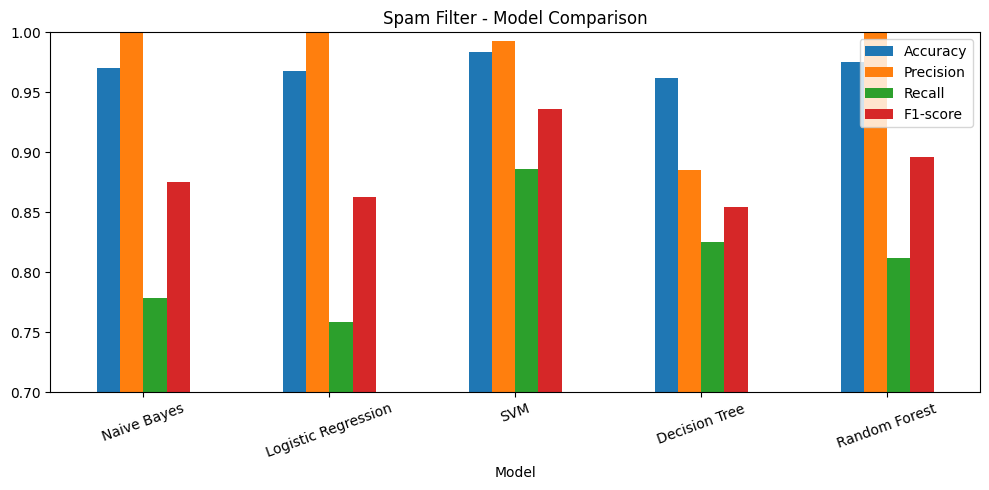

In [ ]:
results.plot(kind="bar", figsize=(10, 5))
plt.title("Spam Filter - Model Comparison")
plt.ylim(0.7, 1.0)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
best = models[results["F1-score"].idxmax()]
tests = ["Congratulations! You won a free prize. Click now to claim",
         "Hi, please find the lab report attached for tomorrow"]
for t in tests:
    label = best.predict(tfidf.transform([t]))[0]
    print("SPAM" if label == 1 else "HAM ", "->", t)

SPAM -> Congratulations! You won a free prize. Click now to claim
HAM  -> Hi, please find the lab report attached for tomorrow
